# Multi-wavelength HK calibration (closure)

The paper's calibration recipe (`lucid.fitting.CalibrationParams` + `closure_data` + `calibrate`) on HK
geometry at the HK laser wavelengths (337, 355, 375, 395, 440, 500 nm), with WCSim optics and real
injector diffusers. Scattering, absorption and QE are free per wavelength; wall / PMT reflection and
the per-PMT gains are shared across wavelengths, which is what separates absorption from reflection.
Settings are constants at the top of `hk_multiwavelength_job.py`; this notebook only loads and plots.

In [1]:
import sys

!cd .. && {sys.executable} hk_multiwavelength_job.py --gpu 5 --out results/hk_nfwd4_resume.npz --seed 3 --resume results/hk_nfwd4.npz


[CudaDevice(id=0)]
19746 PMTs | 5 sources x 6 wavelengths | 22 parameters
[time] truth (100 draws): 201 s
resuming from results/hk_nfwd4.npz

[time] Fisher (8 Jacobian draws): 35 s
param                       sigma  most correlated with
scatter_length_337          0.03%  absorption_length_337 (-0.63)
absorption_length_337       1.01%  qe_337 (-0.88)
qe_337                      0.08%  absorption_length_337 (-0.88)
scatter_length_355          0.03%  absorption_length_355 (-0.63)
absorption_length_355       1.05%  qe_355 (-0.88)
qe_355                      0.08%  absorption_length_355 (-0.88)
scatter_length_375          0.04%  absorption_length_375 (-0.63)
absorption_length_375       0.98%  qe_375 (-0.89)
qe_375                      0.08%  absorption_length_375 (-0.89)
scatter_length_395          0.04%  wall_R (+0.64)
absorption_length_395       0.80%  qe_395 (-0.90)
qe_395                      0.08%  absorption_length_395 (-0.90)
scatter_length_440          0.06%  wall_R (+0.65)
absorpti

In [6]:
import numpy as np
import matplotlib.pyplot as plt

r = np.load('../results/hk_nfwd4_resume.npz')
names, truth, start, fit, free = list(r['names']), r['truth'], r['start'], r['fit'], r['free']
wls = list(r['wavelengths'])
err = fit / truth - 1

print(f'{len(r["source_labels"])} sources x {len(wls)} wavelengths | intensity {float(r["intensity"]):.0e} | seed {int(r["seed"])}')
print(f'{"param":24s}{"truth":>10s}{"start":>10s}{"fit":>10s}{"err":>9s}')
for n, tr, st, ft, e, fr in zip(names, truth, start, fit, err, free):
    print(f'{n:24s}{tr:10.4g}{st:10.4g}{ft:10.4g}{e:+9.1%}' + ('' if fr else '  (fixed)'))
print(f'\nper-PMT gain residual RMS: {np.std(r["gains"] / r["truth_k"] - 1):.2%}')

5 sources x 6 wavelengths | intensity 1e+08 | seed 3
param                        truth     start       fit      err
scatter_length_337            56.9     56.93     56.95    +0.1%
absorption_length_337        830.7     818.5     809.5    -2.5%
qe_337                      0.3065    0.3072    0.3074    +0.3%
scatter_length_355            73.8     73.87     73.84    +0.0%
absorption_length_355        853.4     815.8     830.7    -2.7%
qe_355                      0.3689    0.3706      0.37    +0.3%
scatter_length_375            96.6      96.7     96.69    +0.1%
absorption_length_375        768.1     750.9     754.3    -1.8%
qe_375                      0.4005    0.4018    0.4016    +0.3%
scatter_length_395           124.3     124.5     124.4    +0.1%
absorption_length_395        599.3     579.4     583.4    -2.7%
qe_395                      0.4072    0.4092    0.4088    +0.4%
scatter_length_440           208.1     208.5     208.5    +0.2%
absorption_length_440        247.4     244.8     24

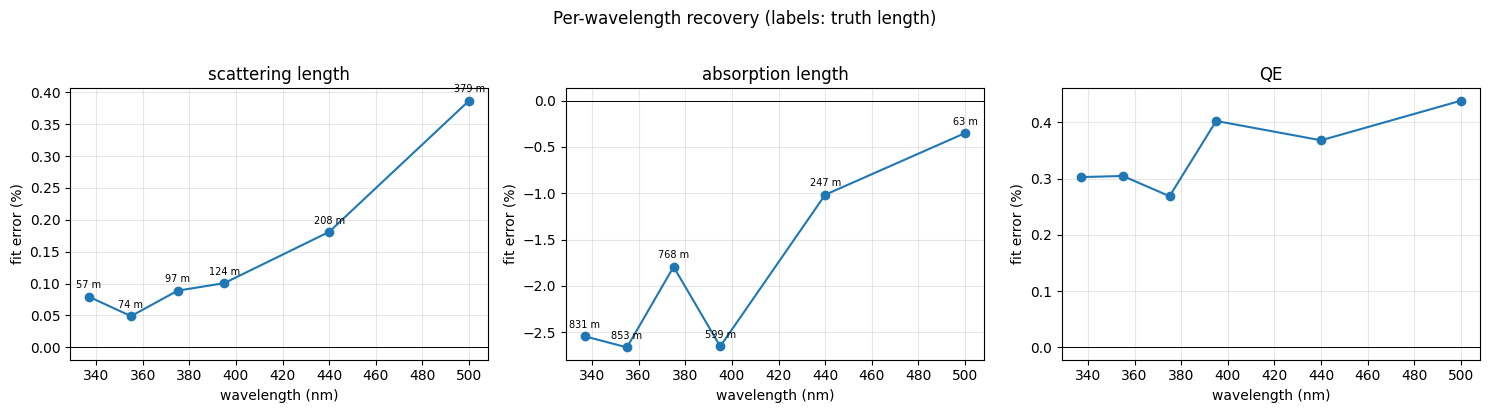

In [7]:
W = len(wls)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, (q, label) in enumerate([('scatter_length', 'scattering length'),
                                 ('absorption_length', 'absorption length'), ('qe', 'QE')]):
    e = np.array([err[names.index(f'{q}_{w}')] for w in wls])
    tv = np.array([truth[names.index(f'{q}_{w}')] for w in wls])
    ax[i].plot(wls, 100 * e, 'o-')
    ax[i].axhline(0, color='k', lw=.7)
    ax[i].set(xlabel='wavelength (nm)', ylabel='fit error (%)', title=label)
    ax[i].grid(alpha=.3)
    if q != 'qe':
        for w, t, y in zip(wls, tv, 100 * e):
            ax[i].annotate(f'{t:.0f} m', (w, y), textcoords='offset points', xytext=(0, 6),
                           ha='center', fontsize=7)
fig.suptitle('Per-wavelength recovery (labels: truth length)', y=1.02)
fig.tight_layout(); plt.show()

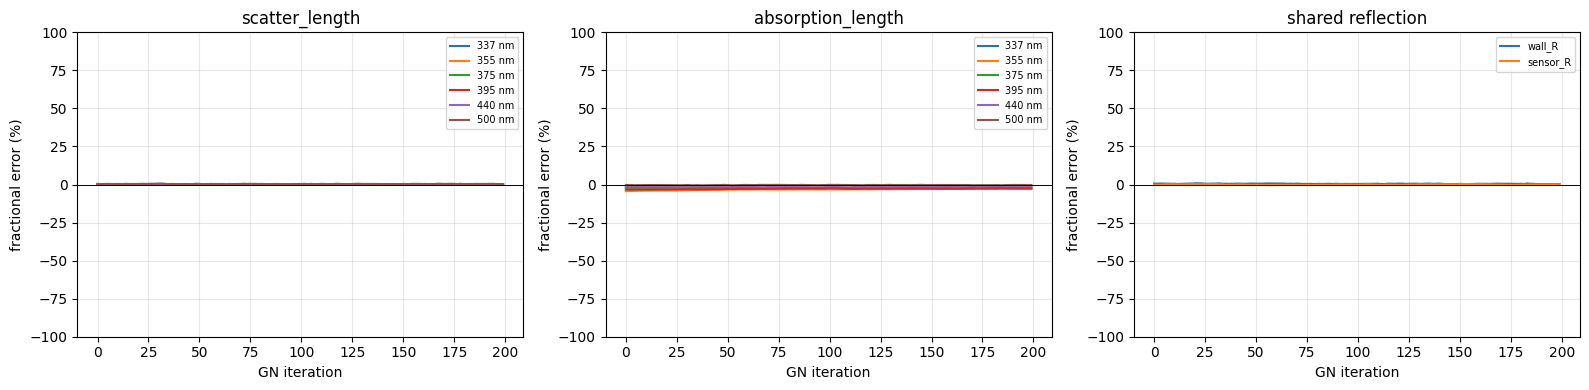

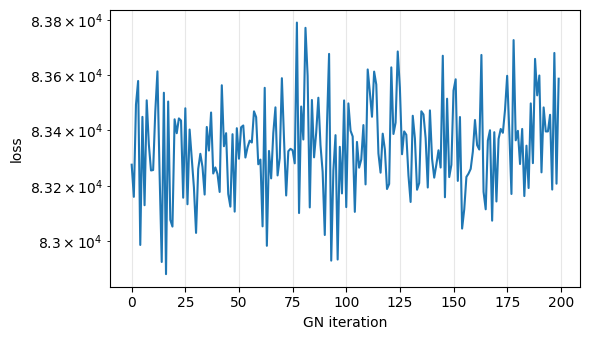

In [8]:
h = r['history'] / truth - 1
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, q in enumerate(['scatter_length', 'absorption_length']):
    for w in wls:
        ax[i].plot(100 * h[:, names.index(f'{q}_{w}')], label=f'{w} nm')
    ax[i].set(title=q, ylim=(-100, 100))
for n in ['wall_R', 'wall_fspec', 'sensor_R', 'sensor_fspec']:
    if free[names.index(n)]:
        ax[2].plot(100 * h[:, names.index(n)], label=n)
ax[2].set(title='shared reflection', ylim=(-100, 100))
for a in ax:
    a.axhline(0, color='k', lw=.7); a.set(xlabel='GN iteration', ylabel='fractional error (%)')
    a.grid(alpha=.3); a.legend(fontsize=7)
fig.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5)); plt.semilogy(r['loss']); plt.xlabel('GN iteration'); plt.ylabel('loss')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

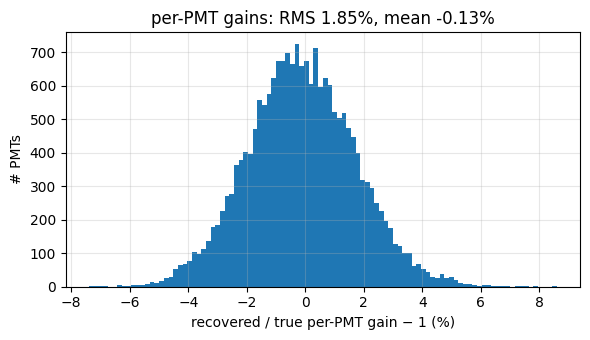

In [9]:
d = r['gains'] / r['truth_k'] - 1
plt.figure(figsize=(6, 3.5))
plt.hist(100 * d, bins=100)
plt.xlabel('recovered / true per-PMT gain − 1 (%)'); plt.ylabel('# PMTs')
plt.title(f'per-PMT gains: RMS {np.std(d):.2%}, mean {np.mean(d):+.2%}')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

chi2 fit - truth = -3275.0 +- 1940.0  (10/16 draws favour the fit; < 0: minimum displaced from truth)



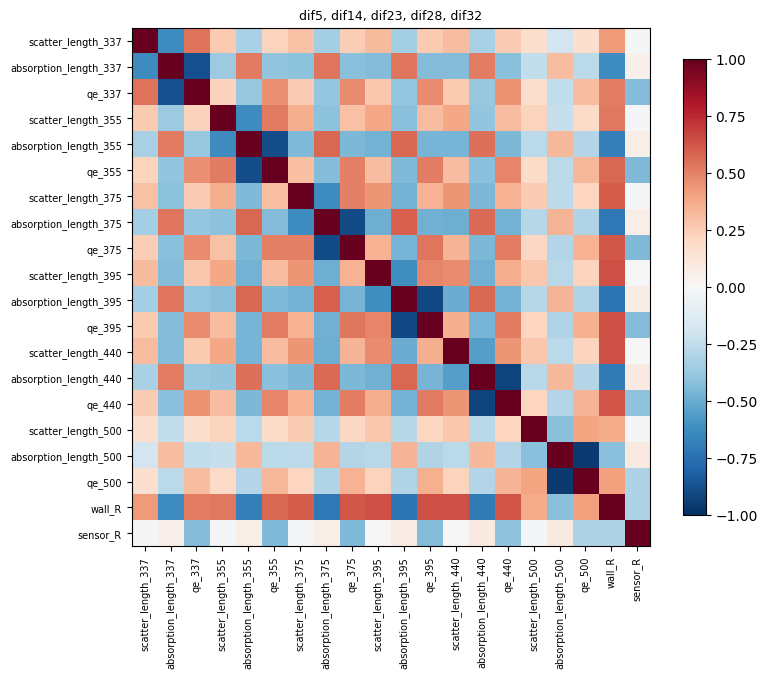

param                          sigma
scatter_length_337             0.03%
absorption_length_337          1.01%
qe_337                         0.08%
scatter_length_355             0.03%
absorption_length_355          1.05%
qe_355                         0.08%
scatter_length_375             0.04%
absorption_length_375          0.98%
qe_375                         0.08%
scatter_length_395             0.04%
absorption_length_395          0.80%
qe_395                         0.08%
scatter_length_440             0.06%
absorption_length_440          0.37%
qe_440                         0.09%
scatter_length_500             0.10%
absorption_length_500          0.13%
qe_500                         0.13%
wall_R                         0.26%
sensor_R                       0.16%

corr(abs_len_wl, X)          337     355     375     395     440     500
wall_R                     -0.63   -0.69   -0.72   -0.73   -0.70   -0.42
sensor_R                   +0.05   +0.06   +0.07   +0.07   +0.09   +0.09
sca

In [10]:
# chi2(fit) vs chi2(truth) check and Fisher at truth (gains marginalised), for the run loaded above.
# sigma: the Poisson bound for this photon budget (Q in real p.e.), so no sqrt(12) factor applies.
if 'chi2_fit' in r.files and r['chi2_fit'].size:
    d = r['chi2_fit'] - r['chi2_truth']
    print(f'chi2 fit - truth = {d.mean():+.1f} +- {d.std(ddof=1) / np.sqrt(d.size):.1f}  '
          f'({(d < 0).sum()}/{d.size} draws favour the fit; < 0: minimum displaced from truth)\n')

if 'corr' in r.files:
    fn, c, sig = list(r['fisher_names']), r['corr'], r['sigma']
    plt.figure(figsize=(8, 7))
    plt.imshow(c, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar(shrink=.8)
    plt.xticks(range(len(fn)), fn, rotation=90, fontsize=7); plt.yticks(range(len(fn)), fn, fontsize=7)
    plt.title(', '.join(r['source_labels']), fontsize=9); plt.tight_layout(); plt.show()

    print(f'{"param":24s}{"sigma":>12s}')
    for n, s in zip(fn, sig):
        print(f'{n:24s}{s:12.2%}')

    print(f'\n{"corr(abs_len_wl, X)":24s}' + ''.join(f'{w:>8d}' for w in wls))
    for x in ('wall_R', 'sensor_R', 'scatter_length'):
        cols = [fn.index(x if x in fn else f'{x}_{w}') for w in wls]
        print(f'{x:24s}' + ''.join(f'{c[fn.index(f"absorption_length_{w}"), j]:+8.2f}' for w, j in zip(wls, cols)))

In [11]:
##split to covariance matrices per wavelength, for the (scatter_length, absorption_length, qe) and all wavelength gain, wall_r, sens_r.


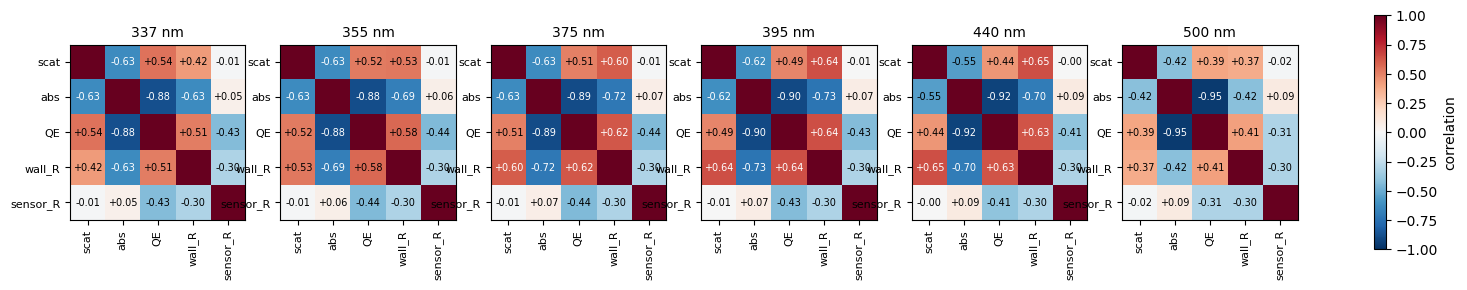

sigma         337      355      375      395      440      500
scat        0.03%    0.03%    0.04%    0.04%    0.06%    0.10%
abs         1.01%    1.05%    0.98%    0.80%    0.37%    0.13%
QE          0.08%    0.08%    0.08%    0.08%    0.09%    0.13%
shared  wall_R 0.26%  sensor_R 0.16%


In [12]:
# Per-wavelength correlation matrices: each λ's own (scattering, absorption, QE) plus the shared
# reflection parameters. These are sub-blocks of the full correlation matrix above, so every
# coefficient is the MARGINAL one (all other parameters free). The per-PMT gains are marginalised
# by the Schur complement inside the Fisher, so they appear in no matrix.
fn, c, sig = list(r['fisher_names']), r['corr'], r['sigma']
short = dict(scatter_length='scat', absorption_length='abs', qe='QE')
shared = [n for n in ('wall_R', 'sensor_R', 'wall_fspec', 'sensor_fspec') if n in fn]

def label(n):
    q = n.rsplit('_', 1)[0]
    return short.get(q, n)

fig, axes = plt.subplots(1, len(wls), figsize=(3.3 * len(wls), 3.8), squeeze=False)
for a, w in zip(axes[0], wls):
    sel = [f'{q}_{w}' for q in short] + shared
    idx = [fn.index(n) for n in sel]
    sub = c[np.ix_(idx, idx)]
    im = a.imshow(sub, cmap='RdBu_r', vmin=-1, vmax=1)
    a.set_xticks(range(len(sel))); a.set_xticklabels([label(n) for n in sel], rotation=90, fontsize=8)
    a.set_yticks(range(len(sel))); a.set_yticklabels([label(n) for n in sel], fontsize=8)
    for i in range(len(sel)):
        for j in range(len(sel)):
            if i != j:
                a.text(j, i, f'{sub[i, j]:+.2f}', ha='center', va='center', fontsize=7,
                       color='w' if abs(sub[i, j]) > 0.6 else 'k')
    a.set_title(f'{w} nm', fontsize=10)
fig.colorbar(im, ax=axes[0].tolist(), shrink=.8, label='correlation')
plt.show()

print(f'{"sigma":8s}' + ''.join(f'{w:>9d}' for w in wls))
for q, s in short.items():
    print(f'{s:8s}' + ''.join(f'{sig[fn.index(f"{q}_{w}")]:9.2%}' for w in wls))
print('shared  ' + '  '.join(f'{n} {sig[fn.index(n)]:.2%}' for n in shared))